# Challenge 2: Online Shopper Purchasing Intention

Predicting whether an online shopping session results in a purchase (`Revenue`).
Target is imbalanced, so F1 score on the positive class is the primary metric.

## Task 1: Data Preparation

In [1]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

In [2]:
train = pd.read_csv("challenge2_train.csv")
test = pd.read_csv("challenge2_test.csv")

print("Training data shape:", train.shape)
print("Test data shape:", test.shape)

display(train.head())

Training data shape: (9247, 19)
Test data shape: (3083, 18)


,ID,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,1,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,3,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
2,4,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
3,7,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False,False
4,9,0,0.0,0,0.0,2,37.000000,0.00,0.10,0.0,0.8,Feb,2,2,2,3,Returning_Visitor,False,False


In [3]:
train.info()

print("\nMissing values in train:", train.isna().sum().sum())
print("Missing values in test:", test.isna().sum().sum())
print("Duplicate IDs in train:", train["ID"].duplicated().sum())
print("ID overlap between train and test:", len(set(train["ID"]) & set(test["ID"])))

<class 'pandas.DataFrame'>
RangeIndex: 9247 entries, 0 to 9246
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       9247 non-null   int64  
 1   Administrative           9247 non-null   int64  
 2   Administrative_Duration  9247 non-null   float64
 3   Informational            9247 non-null   int64  
 4   Informational_Duration   9247 non-null   float64
 5   ProductRelated           9247 non-null   int64  
 6   ProductRelated_Duration  9247 non-null   float64
 7   BounceRates              9247 non-null   float64
 8   ExitRates                9247 non-null   float64
 9   PageValues               9247 non-null   float64
 10  SpecialDay               9247 non-null   float64
 11  Month                    9247 non-null   str    
 12  OperatingSystems         9247 non-null   int64  
 13  Browser                  9247 non-null   int64  
 14  Region                   9247 non-n

In [4]:
display(train.describe().T)

,count,mean,std,min,25%,50%,75%,max
ID,9247.0,6133.869579,3560.547325,1.0,3059.500000,6103.000000,9235.500000,12330.000000
Administrative,9247.0,2.314372,3.319935,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,9247.0,81.168776,179.593423,0.0,0.000000,8.000000,92.550000,3398.750000
Informational,9247.0,0.502433,1.272332,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,9247.0,34.517405,141.310276,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,9247.0,31.358170,43.539969,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,9247.0,1181.847920,1908.101262,0.0,181.416667,598.250000,1464.986002,63973.522230
BounceRates,9247.0,0.022268,0.048680,0.0,0.000000,0.003030,0.016834,0.200000
ExitRates,9247.0,0.043231,0.048835,0.0,0.014286,0.025088,0.050000,0.200000
PageValues,9247.0,5.983551,18.753351,0.0,0.000000,0.000000,0.000000,361.763742


In [5]:
print(train["Revenue"].value_counts())
print("\nPositive class rate:", round(train["Revenue"].mean(), 4))
print("Majority-class baseline accuracy:", round(1 - train["Revenue"].mean(), 4))

Revenue
False    7816
True     1431
Name: count, dtype: int64

Positive class rate: 0.1548
Majority-class baseline accuracy: 0.8452


### Class Imbalance

The target is imbalanced: only 15.5% of sessions end in a purchase. A model that
predicts `False` for every session achieves 84.5% accuracy while producing an F1
score of 0 for the positive class. Accuracy is therefore not a usable metric here,
and F1 on `Revenue=True` is used as the primary score throughout.

In [6]:
print("Conversion rate by Month:")
print(train.groupby("Month")["Revenue"].agg(["mean", "count"])
      .sort_values("mean", ascending=False).round(3))

print("\nConversion rate by VisitorType:")
print(train.groupby("VisitorType")["Revenue"].agg(["mean", "count"]).round(3))

print("\nConversion rate by Weekend:")
print(train.groupby("Weekend")["Revenue"].agg(["mean", "count"]).round(3))

Conversion rate by Month:
        mean  count
Month              
Nov    0.248   2213
Oct    0.224    415
Sep    0.197    345
Aug    0.185    319
Jul    0.135    319
Dec    0.132   1296
May    0.108   2550
Mar    0.104   1445
June   0.103    204
Feb    0.014    141

Conversion rate by VisitorType:
                    mean  count
VisitorType                    
New_Visitor        0.247   1265
Other              0.181     72
Returning_Visitor  0.140   7910

Conversion rate by Weekend:
          mean  count
Weekend              
False    0.148   7116
True     0.176   2131


In [7]:
print("Correlation with Revenue:")
print(train.select_dtypes(include=[np.number]).drop(columns=["ID"])
      .assign(Revenue=train["Revenue"].astype(int))
      .corr()["Revenue"].drop("Revenue").sort_values(ascending=False).round(3))

print("\nPageValues == 0 share:", round((train["PageValues"] == 0).mean(), 3))
print("Conversion when PageValues == 0:",
      round(train.loc[train["PageValues"] == 0, "Revenue"].mean(), 4))
print("Conversion when PageValues  > 0:",
      round(train.loc[train["PageValues"] > 0, "Revenue"].mean(), 4))

Correlation with Revenue:
PageValues                 0.504
ProductRelated             0.162
ProductRelated_Duration    0.151
Administrative             0.143
Administrative_Duration    0.100
Informational              0.095
Informational_Duration     0.067
Browser                    0.020
TrafficType                0.000
Region                    -0.007
OperatingSystems          -0.010
SpecialDay                -0.089
BounceRates               -0.154
ExitRates                 -0.214
Name: Revenue, dtype: float64

PageValues == 0 share: 0.777
Conversion when PageValues == 0: 0.0363
Conversion when PageValues  > 0: 0.5685


### Key Findings

`PageValues` is by far the strongest single predictor (correlation 0.504, roughly
triple any other feature). It is zero for 77.7% of sessions, and that split is close
to a natural decision boundary: sessions with `PageValues == 0` convert at 3.6%,
while sessions with `PageValues > 0` convert at 56.9%.

`ExitRates` (-0.214) and `BounceRates` (-0.154) are the next strongest signals, both
negative as expected. `Month` carries real information, ranging from 24.8% conversion
in November down to 1.4% in February. `VisitorType` shows new visitors converting at
24.7% versus 14.0% for returning visitors.

In [8]:
X = train.drop(columns=["ID", "Revenue"])
y = train["Revenue"].astype(int)

X_test = test.drop(columns=["ID"])
test_ids = test["ID"]

print("X shape:", X.shape, "| y positive rate:", round(y.mean(), 4))
print("X_test shape:", X_test.shape)

X shape: (9247, 17) | y positive rate: 0.1548
X_test shape: (3083, 17)


### Feature Types

`OperatingSystems`, `Browser`, `Region`, and `TrafficType` are stored as integers but
are nominal identifiers, not ordered quantities. Treating them as numeric would imply
that Browser 13 is greater than Browser 1, a relationship that does not exist. Their
correlations with the target (0.020, -0.010, -0.007, and 0.000 respectively) confirm
there is no usable linear ordering. They are therefore one-hot encoded alongside
`Month` and `VisitorType`.

Feature lists are defined explicitly rather than inferred from dtype, since dtype
inference would misclassify all four.

In [9]:
numeric_features = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]

categorical_features = [
    "Month", "VisitorType",
    "OperatingSystems", "Browser", "Region", "TrafficType",
]

binary_features = ["Weekend"]

assert set(numeric_features + categorical_features + binary_features) == set(X.columns)
print("All", X.shape[1], "features assigned.")

All 17 features assigned.


### Preprocessing

Numeric features are standardized. Scaling is required here, not optional: K-Nearest
Neighbors and Support Vector Machines are distance-based and would be dominated by
whichever feature has the largest raw range, and Logistic Regression converges poorly
without it. Tree-based models are unaffected by monotonic rescaling, so a single
shared pipeline serves all seven required models.

`handle_unknown="ignore"` guards against a rare category level being absent from an
individual cross-validation fold.

In [10]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("bin", "passthrough", binary_features),
])

print("Output shape after preprocessing:", preprocessor.fit_transform(X).shape)

Output shape after preprocessing: (9247, 74)


## Task 2: Validation Strategy

We use 5-fold **stratified** cross-validation. Stratification preserves the 15.5%
positive rate within every fold; plain K-fold can produce folds whose class balance
drifts enough to make F1 scores incomparable across models.

F1 on the positive class is the primary metric, matching the competition. Precision
and recall are reported alongside it because F1 alone hides which side a model is
failing on, and ROC AUC is included as a threshold-independent check. Accuracy is
reported only to demonstrate how misleading it is at this class balance.

Train-fold and validation-fold F1 are both reported so the gap between them exposes
overfitting. The same `StratifiedKFold` object is reused for every model and carries
forward into GridSearchCV during tuning.

Note for the tuning stage: `class_weight="balanced"` is available on Logistic
Regression, SVM, Decision Tree, and Random Forest, and is likely to improve F1
meaningfully at this class balance. It belongs in the hyperparameter grid rather
than in preprocessing.

### Development and Holdout Split

The training data is split into a development set (85%) and a holdout set (15%),
stratified to preserve the class balance in both. All cross-validation, hyperparameter
tuning, and model comparison use the development set only.

The holdout is evaluated exactly once, during final model selection, as a check on
whether cross-validation results held up on data that played no part in tuning. At
roughly 215 positive cases it is large enough to catch a model that benefited from
fold-specific noise, but not large enough to serve as the selection metric itself.

In [11]:
from sklearn.model_selection import train_test_split

X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)

print("Development set:", X_dev.shape, "| positive rate:", round(y_dev.mean(), 4))
print("Holdout set:    ", X_holdout.shape, "| positive rate:", round(y_holdout.mean(), 4))

Development set: (7859, 17) | positive rate: 0.1547
Holdout set:     (1388, 17) | positive rate: 0.1549


In [12]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Serial folds avoid multiprocessing resource-tracker issues on Windows.
# Increase only if your environment supports parallel workers reliably.
CV_N_JOBS = 1

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

SCORING = {
    "f1": "f1",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
}

def cv_evaluate(name, model):
    results = cross_validate(
        model, X_dev, y_dev,
        cv=cv,
        scoring=SCORING,
        return_train_score=True,
        error_score="raise",
        n_jobs=CV_N_JOBS,
    )
    return {
        "Model": name,
        "Train F1": results["train_f1"].mean(),
        "CV F1": results["test_f1"].mean(),
        "F1 Std": results["test_f1"].std(),
        "Gap": results["train_f1"].mean() - results["test_f1"].mean(),
        "Precision": results["test_precision"].mean(),
        "Recall": results["test_recall"].mean(),
        "ROC AUC": results["test_roc_auc"].mean(),
        "Accuracy": results["test_accuracy"].mean(),
        "Fit time (s)": results["fit_time"].mean(),
    }

In [13]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

def cv_confusion(name, model):
    preds = cross_val_predict(model, X_dev, y_dev, cv=cv, n_jobs=CV_N_JOBS)   
    print(f"--- {name} ---")
    print(confusion_matrix(y_dev, preds))                             
    print(classification_report(y_dev, preds, target_names=["No Purchase", "Purchase"]))
    return preds

### Decision Threshold

Classifiers default to a 0.5 probability threshold, which is rarely F1-optimal on
imbalanced data. Because F1 on the positive class is the competition metric, the
threshold is treated as a tunable parameter: cross-validated predicted probabilities
are swept across the precision-recall curve and the threshold maximizing F1 is
selected. The threshold is chosen on development-set validation folds only.

In [14]:
from sklearn.metrics import precision_recall_curve, f1_score

def tune_threshold(name, model):
    proba = cross_val_predict(
        model, X_dev, y_dev, cv=cv, method="predict_proba", n_jobs=CV_N_JOBS
    )[:, 1]

    precision, recall, thresholds = precision_recall_curve(y_dev, proba)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    best = f1[:-1].argmax()

    return {
        "Model": name,
        "F1 @ 0.50": f1_score(y_dev, proba >= 0.5),
        "Best threshold": thresholds[best],
        "F1 @ best": f1[best],
    }

## Task 3: Develop and Compare Models

### 3.1 Logistic Regression

The existing Logistic Regression is our linear baseline. All seven classifiers use
the same development rows, five shuffled stratified folds (`random_state=42`), and
positive-class F1 scoring. Preprocessing is cloned and fitted inside each fold.
The 15% holdout is reserved for the later final-model check.

We compare each estimator's **native `predict` rule**, without optimizing its
threshold. For probability-based classifiers this normally corresponds to 0.5;
SVM uses a zero decision-function boundary. Class weights in the existing tree
models are retained; these are specified starting configurations, not the result
of a hyperparameter search. Task 4 can investigate their effect consistently.

The threshold sweep below is an exploratory result from Task 2. Maximizing F1
over these out-of-fold labels makes `F1 @ best` a threshold-selection score, not
an independent estimate of performance at that selected threshold. It is kept
separate from the seven-model comparison. Task 4 must choose thresholds within
training folds (or use nested CV) before claiming a validated improvement.


In [15]:
from sklearn.linear_model import LogisticRegression

baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000)),
])

lr_results = cv_evaluate("Logistic Regression", baseline)
display(pd.DataFrame([lr_results]).round(3))
display(pd.DataFrame([tune_threshold("Logistic Regression (baseline)", baseline)]).round(3))

,Model,Train F1,CV F1,F1 Std,Gap,Precision,Recall,ROC AUC,Accuracy,Fit time (s)
0,Logistic Regression,0.534,0.522,0.027,0.012,0.756,0.4,0.895,0.887,0.039


,Model,F1 @ 0.50,Best threshold,F1 @ best
0,Logistic Regression (baseline),0.523,0.233,0.633


### 3.2 Decision Tree Classifier

A Decision Tree is a supervised machine learning algorithm that makes predictions by splitting the dataset into smaller groups based on feature values.

It can capture nonlinear relationships between different features and the likelihood of a customer making a purchase.

We use parameters such as maximum tree depth and minimum samples per leaf to control model complexity and reduce overfitting. We also use balanced class weights to account for the imbalanced target variable.

The model is evaluated using stratified 5-fold cross-validation to maintain consistency with our previous validation strategy.

In [16]:
from sklearn.tree import DecisionTreeClassifier

# Create a pipeline that preprocesses the data before training the model.
decision_tree = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=10,             # Limits tree depth to reduce overfitting.
        min_samples_split=10,     # Minimum samples required to split a node.
        min_samples_leaf=5,       # Minimum samples required in each leaf.
        class_weight="balanced",  # Gives more importance to the minority class.
        random_state=42           # Ensures reproducible results.
    ))
])

# Evaluate the model using the same stratified 5-fold cross-validation.
dt_results = cv_evaluate("Decision Tree", decision_tree)

# Display the evaluation metrics.
display(pd.DataFrame([dt_results]).round(3))

,Model,Train F1,CV F1,F1 Std,Gap,Precision,Recall,ROC AUC,Accuracy,Fit time (s)
0,Decision Tree,0.728,0.596,0.017,0.132,0.478,0.795,0.859,0.833,0.059


### 3.3 Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to make predictions.

Each tree is trained using different samples of the training data, and their predictions are combined to produce the final result.

Compared to a single Decision Tree, Random Forest generally provides more stable predictions and helps reduce overfitting.

We use 200 trees and limit their maximum depth to control model complexity. Balanced class weights are also applied to address the imbalance in the Revenue target variable.

The model is evaluated using the same stratified 5-fold cross-validation strategy.

In [17]:
from sklearn.ensemble import RandomForestClassifier

random_forest = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,         # Number of decision trees in the forest.
        max_depth=15,             # Limits the maximum depth of each tree.
        min_samples_split=10,     # Minimum samples needed to split a node.
        min_samples_leaf=5,       # Minimum samples required in each leaf.
        class_weight="balanced",  # Accounts for the imbalanced target classes.
        random_state=42,          # Ensures reproducible results.
        n_jobs=1                  # Keep execution portable; avoid nested workers.
    ))
])

# Evaluate the model using stratified 5-fold cross-validation.
rf_results = cv_evaluate("Random Forest", random_forest)

# Display the evaluation metrics.
display(pd.DataFrame([rf_results]).round(3))

,Model,Train F1,CV F1,F1 Std,Gap,Precision,Recall,ROC AUC,Accuracy,Fit time (s)
0,Random Forest,0.755,0.668,0.013,0.087,0.562,0.825,0.93,0.873,1.873


### 3.4 Gradient Boosting Classifier

Gradient Boosting is an ensemble learning algorithm that builds decision trees sequentially.

Each new tree attempts to correct the errors made by the previous trees, gradually improving the model's predictive performance.

We use 100 boosting stages, a learning rate of 0.1, and a maximum tree depth of 3. These parameters control how quickly the model learns and help prevent excessive complexity.

The model is evaluated using stratified 5-fold cross-validation to compare its performance fairly against the other classifiers.

In [18]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(
        n_estimators=100,     # Number of boosting stages (trees).
        learning_rate=0.1,    # Controls the contribution of each new tree.
        max_depth=3,          # Limits the complexity of individual trees.
        random_state=42       # Ensures reproducible results.
    ))
])

# Evaluate the model using stratified 5-fold cross-validation.
gb_results = cv_evaluate("Gradient Boosting", gradient_boosting)

# Display the evaluation metrics.
display(pd.DataFrame([gb_results]).round(3))

,Model,Train F1,CV F1,F1 Std,Gap,Precision,Recall,ROC AUC,Accuracy,Fit time (s)
0,Gradient Boosting,0.744,0.673,0.024,0.071,0.726,0.628,0.933,0.906,0.713


### 3.5 Naïve Bayes

Gaussian Naïve Bayes is a fast probabilistic baseline. It assumes conditional
independence and Gaussian feature distributions within each class. The session
variables are skewed and the encoded category indicators are binary, so these
assumptions are approximations; validation will show whether they are adequate.
This is GaussianNB rather than MultinomialNB, because standardized numeric inputs
can be negative and are not event counts.

GaussianNB requires dense input. Its own cloned preprocessor disables sparse
one-hot output; this changes storage only and keeps the same features and
fold-local standardization. The other pipelines retain their original encoding.

In [19]:
from sklearn.base import clone
from sklearn.naive_bayes import GaussianNB

nb_preprocessor = clone(preprocessor).set_params(cat__sparse_output=False)
naive_bayes = Pipeline([
    ("preprocessor", nb_preprocessor),
    ("model", GaussianNB()),
])

nb_results = cv_evaluate("Naive Bayes", naive_bayes)
display(pd.DataFrame([nb_results]).round(3))

,Model,Train F1,CV F1,F1 Std,Gap,Precision,Recall,ROC AUC,Accuracy,Fit time (s)
0,Naive Bayes,0.307,0.305,0.009,0.002,0.181,0.976,0.743,0.31,0.014


### 3.6 K-Nearest Neighbors

KNN predicts from the majority class among the five nearest training sessions.
Numeric features are standardized within each fold so durations do not dominate
the distance. The categorical variables remain one-hot encoded. We start with
five uniformly weighted neighbors and Euclidean distance (`p=2`). Many category
indicators and the majority class can make nearby purchases difficult to identify;
precision and recall help explain the resulting F1. Neighbor count and weighting
are candidates for Task 4, not tuned here.

In [20]:
from sklearn.neighbors import KNeighborsClassifier

knn = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", KNeighborsClassifier(n_neighbors=5, weights="uniform", p=2)),
])

knn_results = cv_evaluate("K-Nearest Neighbors", knn)
display(pd.DataFrame([knn_results]).round(3))

,Model,Train F1,CV F1,F1 Std,Gap,Precision,Recall,ROC AUC,Accuracy,Fit time (s)
0,K-Nearest Neighbors,0.606,0.48,0.026,0.126,0.664,0.377,0.803,0.874,0.011


### 3.7 Support Vector Machine

An RBF-kernel SVM allows a nonlinear decision boundary. Numeric scaling is fitted
within each fold. We use starting settings `C=1.0`, `gamma="scale"`, and no class
weight adjustment, as with the Logistic Regression baseline. `C`, `gamma`, and
class weighting can be investigated with Grid Search later.

We use SVC's native decision scores without requesting probability calibration. ROC AUC uses
the decision function, and F1, precision, recall, accuracy and confusion matrices
use `predict`. Thus no calibrated probabilities are required for this comparison.
An RBF SVM can take longer to fit than a linear model and is harder to interpret.

In [21]:
from sklearn.svm import SVC

svm = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", SVC(C=1.0, kernel="rbf", gamma="scale")),
])

svm_results = cv_evaluate("Support Vector Machine", svm)
display(pd.DataFrame([svm_results]).round(3))

,Model,Train F1,CV F1,F1 Std,Gap,Precision,Recall,ROC AUC,Accuracy,Fit time (s)
0,Support Vector Machine,0.664,0.601,0.029,0.064,0.755,0.5,0.888,0.897,0.559


### 3.8 Compare all seven models

The table is ranked by mean validation-fold **F1 for `Revenue=True`**. Precision,
recall, ROC AUC and accuracy are also fold means. `Train F1` is the mean score on
the training portion of each fold, and `Gap = Train F1 - CV F1`; a larger positive
gap is evidence of overfitting. `F1 Std` is the population standard deviation over
the five validation folds, **not a confidence interval**. Fit time is the mean
per fold on this machine; it includes preprocessing and is affected by parallelism.

All rows use the same native-prediction comparison. The optimized Logistic
Regression threshold score is deliberately excluded. No holdout labels or test
features are used in these model fits or comparisons.

In [22]:
models = {
    "Logistic Regression": baseline,
    "Naive Bayes": naive_bayes,
    "K-Nearest Neighbors": knn,
    "Support Vector Machine": svm,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "Gradient Boosting": gradient_boosting,
}

comparison_df = (
    pd.DataFrame([
        lr_results, nb_results, knn_results, svm_results,
        dt_results, rf_results, gb_results,
    ])
    .sort_values(["CV F1", "Model"], ascending=[False, True])
    .reset_index(drop=True)
)
assert len(comparison_df) == 7
assert set(comparison_df["Model"]) == set(models)
assert np.isfinite(comparison_df.select_dtypes(include=np.number)).all().all()
display(comparison_df.round(3))

# Save full precision so the table can be used during Task 4.
comparison_df.to_csv("task3_model_comparison.csv", index=False)

,Model,Train F1,CV F1,F1 Std,Gap,Precision,Recall,ROC AUC,Accuracy,Fit time (s)
0,Gradient Boosting,0.744,0.673,0.024,0.071,0.726,0.628,0.933,0.906,0.713
1,Random Forest,0.755,0.668,0.013,0.087,0.562,0.825,0.930,0.873,1.873
2,Support Vector Machine,0.664,0.601,0.029,0.064,0.755,0.500,0.888,0.897,0.559
3,Decision Tree,0.728,0.596,0.017,0.132,0.478,0.795,0.859,0.833,0.059
4,Logistic Regression,0.534,0.522,0.027,0.012,0.756,0.400,0.895,0.887,0.039
5,K-Nearest Neighbors,0.606,0.480,0.026,0.126,0.664,0.377,0.803,0.874,0.011
6,Naive Bayes,0.307,0.305,0.009,0.002,0.181,0.976,0.743,0.310,0.014


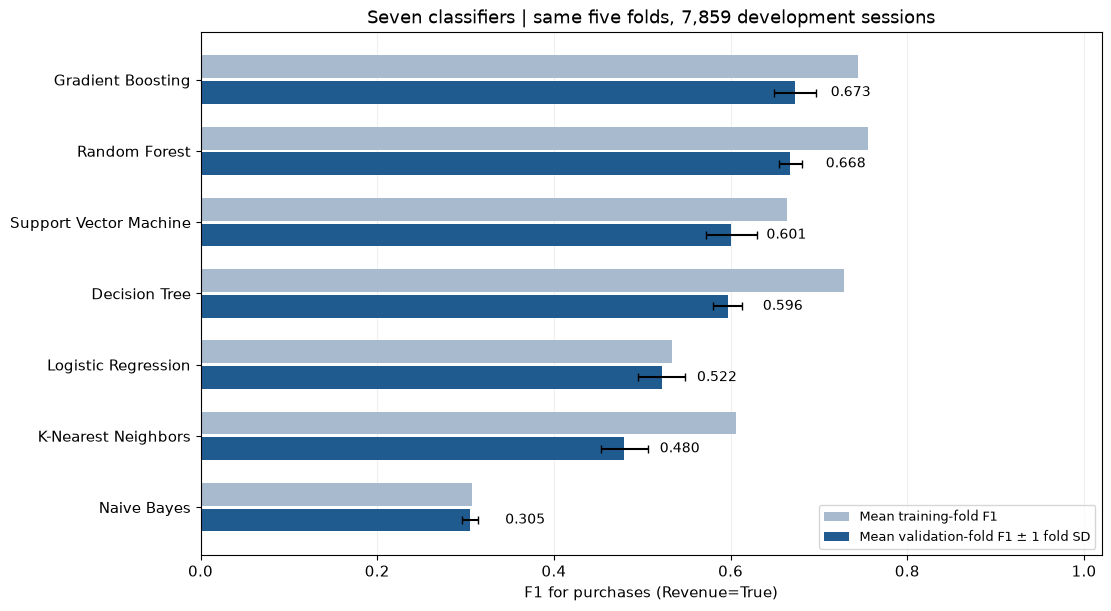

In [23]:
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 11, "axes.titlesize": 13})
plot_df = comparison_df.sort_values("CV F1")
positions = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
ax.barh(positions + 0.18, plot_df["Train F1"], height=0.32,
        color="#a8bacd", label="Mean training-fold F1")
ax.barh(positions - 0.18, plot_df["CV F1"], height=0.32,
        color="#205b8f", xerr=plot_df["F1 Std"], capsize=3,
        label="Mean validation-fold F1 ± 1 fold SD")
for position, value in zip(positions, plot_df["CV F1"]):
    ax.text(min(value + 0.04, 0.94), position - 0.18,
            f"{value:.3f}", va="center", fontsize=10)
ax.set(yticks=positions, yticklabels=plot_df["Model"], xlim=(0, 1.02),
       xlabel="F1 for purchases (Revenue=True)",
       title=f"Seven classifiers | same five folds, {len(X_dev):,} development sessions")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="lower right", fontsize=9)
fig.savefig("task3_f1_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.9 Out-of-fold confusion matrices

Each development session is predicted once by a pipeline fitted on the other
four folds. The matrices therefore contain no in-sample predictions. Rows are
actual classes and columns are predicted classes: upper-left TN, upper-right FP,
lower-left FN, lower-right TP. Absolute counts and a shared color scale make the
different precision/recall tradeoffs visible.

These are pooled out-of-fold counts across 7,859 development sessions. F1 computed
from the pooled counts can differ slightly from the mean of five fold-specific
F1 scores used to rank the table. The holdout remains unused.

,Model,TN,FP,FN,TP,Pooled OOF F1
0,Gradient Boosting,6353,290,452,764,0.673
1,Random Forest,5857,786,213,1003,0.668
2,Support Vector Machine,6443,200,608,608,0.601
3,Decision Tree,5583,1060,249,967,0.596
4,Logistic Regression,6485,158,730,486,0.523
5,K-Nearest Neighbors,6410,233,758,458,0.480
6,Naive Bayes,1251,5392,29,1187,0.305


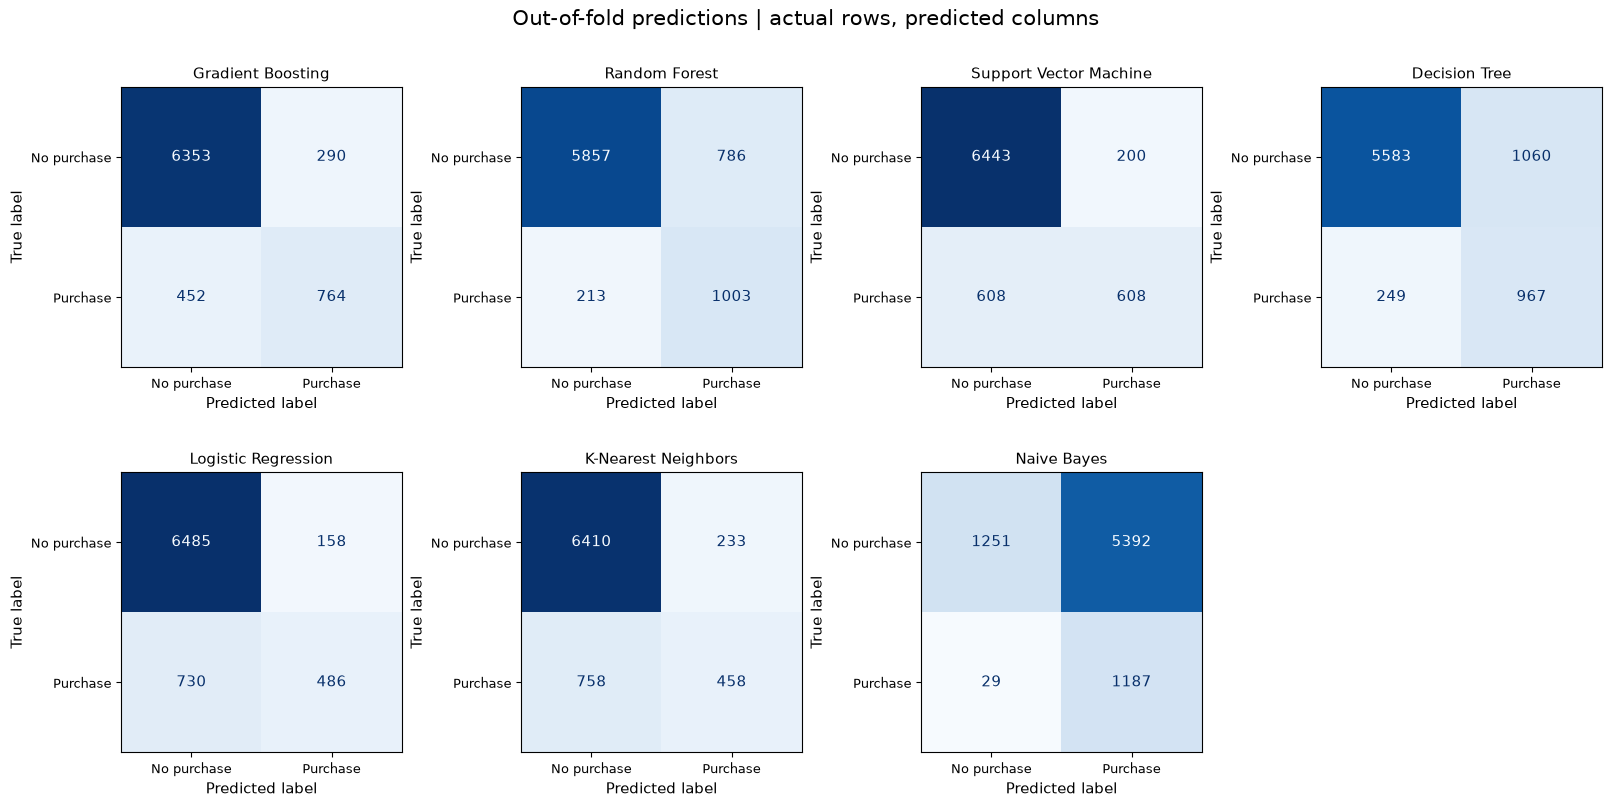

Development OOF classification report: Gradient Boosting
              precision    recall  f1-score   support

 No Purchase      0.934     0.956     0.945      6643
    Purchase      0.725     0.628     0.673      1216

    accuracy                          0.906      7859
   macro avg      0.829     0.792     0.809      7859
weighted avg      0.901     0.906     0.903      7859



In [24]:
from sklearn.metrics import ConfusionMatrixDisplay

oof_predictions = pd.DataFrame(index=X_dev.index)
confusion_rows = []
for name in comparison_df["Model"]:
    predictions = cross_val_predict(
        models[name], X_dev, y_dev, cv=cv, n_jobs=CV_N_JOBS,
    )
    oof_predictions[name] = predictions
    tn, fp, fn, tp = confusion_matrix(y_dev, predictions, labels=[0, 1]).ravel()
    confusion_rows.append({
        "Model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Pooled OOF F1": f1_score(y_dev, predictions, pos_label=1),
    })

confusion_df = pd.DataFrame(confusion_rows)
display(confusion_df.round(3))
confusion_df.to_csv("task3_confusion_counts.csv", index=False)

fig, axes = plt.subplots(2, 4, figsize=(16, 8), layout="constrained")
max_count = int(confusion_df[["TN", "FP", "FN", "TP"]].to_numpy().max())
for ax, name in zip(axes.flat, comparison_df["Model"]):
    matrix = confusion_matrix(y_dev, oof_predictions[name], labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["No purchase", "Purchase"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d",
        im_kw={"vmin": 0, "vmax": max_count},
    )
    ax.set_title(name, fontsize=11)
    ax.tick_params(axis="both", labelsize=9)
axes.flat[-1].set_visible(False)
fig.suptitle("Out-of-fold predictions | actual rows, predicted columns", fontsize=15)
fig.savefig("task3_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

leading_model = comparison_df.iloc[0]["Model"]
print(f"Development OOF classification report: {leading_model}")
print(classification_report(
    y_dev, oof_predictions[leading_model], labels=[0, 1],
    target_names=["No Purchase", "Purchase"], digits=3, zero_division=0,
))

### 3.10 Interpret the results and hand off to model improvement

The summary below is generated from the executed comparison, so it stays aligned
with the results when the notebook is rerun. The top rows are candidates for
Grid Search in Task 4. This section does not select or refit a final model,
evaluate the holdout, or generate competition predictions.

In [25]:
from IPython.display import Markdown

leader = comparison_df.iloc[0]
runner_up = comparison_df.iloc[1]
display(Markdown(
    f"**{leader['Model']} has the highest starting CV F1: "
    f"{leader['CV F1']:.3f} (fold SD {leader['F1 Std']:.3f}).** "
    f"Its mean precision is {leader['Precision']:.3f} and recall is "
    f"{leader['Recall']:.3f}, with a train/validation F1 gap of {leader['Gap']:.3f}. "
    f"The next model is {runner_up['Model']} at {runner_up['CV F1']:.3f}. "
    "Small differences across these reused folds do not establish a reliable "
    "generalization advantage; model selection itself can make CV results optimistic."
))

for _, row in comparison_df.iterrows():
    display(Markdown(
        f"- **{row['Model']}:** CV F1 {row['CV F1']:.3f}; "
        f"precision {row['Precision']:.3f}, recall {row['Recall']:.3f}; "
        f"train/validation gap {row['Gap']:.3f}; "
        f"mean fold fit time {row['Fit time (s)']:.2f} s."
    ))

display(Markdown(
    "Logistic Regression provides an interpretable linear reference; its precision "
    "and recall show whether the native threshold misses purchases. Gaussian Naive "
    "Bayes is fast but its conditional-independence and distribution assumptions "
    "can limit F1 on these mixed features. KNN depends on local distances and can "
    "lose minority-class neighbors in one-hot feature space. The nonlinear SVM "
    "can capture a more flexible boundary, at greater fitting and explanation cost. "
    "A single tree is easy to inspect but its train/validation gap signals how much "
    "its rules overfit. Random Forest averages trees; Gradient Boosting combines "
    "successive corrections. Their F1, gaps, and fit times show the tradeoff rather "
    "than assuming that either ensemble must win."
))

tuning_candidates = comparison_df.head(2)["Model"].tolist()
display(Markdown(
    f"**Task 4 starting point:** tune {tuning_candidates[0]} and "
    f"{tuning_candidates[1]} with `GridSearchCV(scoring='f1', cv=cv)` on "
    "`X_dev, y_dev`, keeping preprocessing in the pipeline. Consider class weights "
    "and appropriately nested threshold tuning as separate improvements. Freeze "
    "the model and threshold before using the holdout once for a final check. "
    "Only then refit on all labeled training rows and generate test predictions "
    "in Tasks 5–6."
))

**Gradient Boosting has the highest starting CV F1: 0.673 (fold SD 0.024).** Its mean precision is 0.726 and recall is 0.628, with a train/validation F1 gap of 0.071. The next model is Random Forest at 0.668. Small differences across these reused folds do not establish a reliable generalization advantage; model selection itself can make CV results optimistic.

- **Gradient Boosting:** CV F1 0.673; precision 0.726, recall 0.628; train/validation gap 0.071; mean fold fit time 0.71 s.

- **Random Forest:** CV F1 0.668; precision 0.562, recall 0.825; train/validation gap 0.087; mean fold fit time 1.87 s.

- **Support Vector Machine:** CV F1 0.601; precision 0.755, recall 0.500; train/validation gap 0.064; mean fold fit time 0.56 s.

- **Decision Tree:** CV F1 0.596; precision 0.478, recall 0.795; train/validation gap 0.132; mean fold fit time 0.06 s.

- **Logistic Regression:** CV F1 0.522; precision 0.756, recall 0.400; train/validation gap 0.012; mean fold fit time 0.04 s.

- **K-Nearest Neighbors:** CV F1 0.480; precision 0.664, recall 0.377; train/validation gap 0.126; mean fold fit time 0.01 s.

- **Naive Bayes:** CV F1 0.305; precision 0.181, recall 0.976; train/validation gap 0.002; mean fold fit time 0.01 s.

Logistic Regression provides an interpretable linear reference; its precision and recall show whether the native threshold misses purchases. Gaussian Naive Bayes is fast but its conditional-independence and distribution assumptions can limit F1 on these mixed features. KNN depends on local distances and can lose minority-class neighbors in one-hot feature space. The nonlinear SVM can capture a more flexible boundary, at greater fitting and explanation cost. A single tree is easy to inspect but its train/validation gap signals how much its rules overfit. Random Forest averages trees; Gradient Boosting combines successive corrections. Their F1, gaps, and fit times show the tradeoff rather than assuming that either ensemble must win.

**Task 4 starting point:** tune Gradient Boosting and Random Forest with `GridSearchCV(scoring='f1', cv=cv)` on `X_dev, y_dev`, keeping preprocessing in the pipeline. Consider class weights and appropriately nested threshold tuning as separate improvements. Freeze the model and threshold before using the holdout once for a final check. Only then refit on all labeled training rows and generate test predictions in Tasks 5–6.

## Task 4: Improve Models with Grid Search

Gradient Boosting and Random Forest had the strongest starting cross-validation
F1 scores, so we tune these two models. We retain the same `X_dev`, `y_dev` and
five shuffled stratified folds from Tasks 2–3. Every candidate is a full pipeline:
scaling and one-hot encoding are fitted separately inside each training fold.
Neither the holdout nor the competition test data is used in this search.

`GridSearchCV` selects parameters using positive-class F1 (`refit="f1"`). We also
record precision, recall, ROC AUC, training F1, fold standard deviation and fit
time. Predictions retain each classifier's native rule; the exploratory threshold
sweep from Task 2 is not used to select parameters or claim an improvement.

The grids include the original configurations, allowing a direct comparison with
Task 3. We keep the existing features to isolate the effect of hyperparameters.
Feature engineering is optional and is not added in this experiment.

In [26]:
from sklearn.model_selection import GridSearchCV, ParameterGrid

task4_searches = {}

gb_param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3],
    "model__min_samples_leaf": [1, 10],
}

rf_param_grid = {
    "model__max_depth": [10, 15, None],
    "model__min_samples_leaf": [2, 5],
    "model__class_weight": [None, "balanced"],
}

# Random Forest retains 200 trees and min_samples_split=10 from Task 3.
for name, grid in [("Gradient Boosting", gb_param_grid), ("Random Forest", rf_param_grid)]:
    candidates = len(ParameterGrid(grid))
    print(f"{name}: {candidates} configurations, {candidates * cv.get_n_splits()} CV fits")

Gradient Boosting: 16 configurations, 80 CV fits
Random Forest: 12 configurations, 60 CV fits


### 4.1 Tune Gradient Boosting

We vary the number of boosting stages and learning rate together because smaller
updates may need more trees. Depth and minimum leaf size control how complex each
tree can become. Shallower trees or larger leaves may reduce the train/validation
gap, at the cost of underfitting if regularization is too strong.

In [27]:
gb_search = GridSearchCV(
    clone(gradient_boosting), gb_param_grid,
    scoring=SCORING, refit="f1", cv=cv,
    return_train_score=True, error_score="raise", n_jobs=CV_N_JOBS,
)
gb_search.fit(X_dev, y_dev)
task4_searches["Gradient Boosting"] = gb_search
print("Best Gradient Boosting parameters:", gb_search.best_params_)
print(f"Best mean CV F1: {gb_search.best_score_:.4f}")

Best Gradient Boosting parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Best mean CV F1: 0.6799


### 4.2 Tune Random Forest

We compare limited and unrestricted depth, smaller and larger leaves, and balanced
versus unweighted classes. Class weighting can recover more purchases but can also
increase false positives, so it is selected by F1 rather than assumed to help.
We retain 200 trees to limit computation while testing these regularization and
class-balance choices. All trees retain `random_state=42` and serial fitting.

In [28]:
rf_search = GridSearchCV(
    clone(random_forest), rf_param_grid,
    scoring=SCORING, refit="f1", cv=cv,
    return_train_score=True, error_score="raise", n_jobs=CV_N_JOBS,
)
rf_search.fit(X_dev, y_dev)
task4_searches["Random Forest"] = rf_search
print("Best Random Forest parameters:", rf_search.best_params_)
print(f"Best mean CV F1: {rf_search.best_score_:.4f}")

Best Random Forest parameters: {'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 2}
Best mean CV F1: 0.6788


### 4.3 Compare Starting and Tuned Configurations

The table uses the same metrics and folds as Task 3. `F1 Change` is the absolute
change from that model's starting CV F1; `Gap` is training F1 minus validation F1.
Fit times are means per fold, not total search runtimes. Standard deviations
describe variation across these five folds and are not confidence intervals.

These are **development and parameter-selection results**. Reusing the folds to
select and report the best configuration can make the tuned scores optimistic;
a small improvement is not proof of better generalization. No independent tuned
performance estimate is claimed here. The reserved holdout remains available for
the one-time check after model and threshold selection in Task 5.

In [29]:
task4_rows = []
for name, search in task4_searches.items():
    starting = comparison_df.loc[comparison_df["Model"].eq(name)].iloc[0].to_dict()
    task4_rows.append({**starting, "Configuration": "Starting", "F1 Change": 0.0})
    results = pd.DataFrame(search.cv_results_)
    assert np.isfinite(results["mean_test_f1"]).all()
    results.to_csv(
        f"task4_{name.lower().replace(' ', '_')}_grid.csv", index=False
    )
    best = search.best_index_
    tuned = {
        "Model": name,
        "Configuration": "Tuned",
        "Train F1": results.loc[best, "mean_train_f1"],
        "CV F1": results.loc[best, "mean_test_f1"],
        "F1 Std": results.loc[best, "std_test_f1"],
        "Precision": results.loc[best, "mean_test_precision"],
        "Recall": results.loc[best, "mean_test_recall"],
        "ROC AUC": results.loc[best, "mean_test_roc_auc"],
        "Accuracy": results.loc[best, "mean_test_accuracy"],
        "Fit time (s)": results.loc[best, "mean_fit_time"],
    }
    tuned["Gap"] = tuned["Train F1"] - tuned["CV F1"]
    tuned["F1 Change"] = tuned["CV F1"] - starting["CV F1"]
    # The grid includes the starting configuration, so its best score cannot be worse.
    assert tuned["F1 Change"] >= -1e-10
    task4_rows.append(tuned)

task4_comparison = pd.DataFrame(task4_rows)[[
    "Model", "Configuration", "Train F1", "CV F1", "F1 Std", "Gap",
    "F1 Change", "Precision", "Recall", "ROC AUC", "Accuracy", "Fit time (s)",
]]
assert np.isfinite(task4_comparison.select_dtypes(include=np.number)).all().all()
display(task4_comparison.round(4))
task4_comparison.to_csv("task4_tuning_comparison.csv", index=False)

# Unfitted copies are available for later evaluation; neither is a final selection.
tuned_models = {
    name: clone(search.best_estimator_) for name, search in task4_searches.items()
}

,Model,Configuration,Train F1,CV F1,F1 Std,Gap,F1 Change,Precision,Recall,ROC AUC,Accuracy,Fit time (s)
0,Gradient Boosting,Starting,0.7441,0.6733,0.0238,0.0708,0.0000,0.7265,0.6283,0.9334,0.9056,0.7131
1,Gradient Boosting,Tuned,0.7414,0.6799,0.0225,0.0615,0.0065,0.7362,0.6324,0.9338,0.9078,1.4159
2,Random Forest,Starting,0.7550,0.6677,0.0125,0.0873,0.0000,0.5616,0.8248,0.9300,0.8729,1.8725
3,Random Forest,Tuned,0.8226,0.6788,0.0090,0.1437,0.0111,0.5847,0.8108,0.9313,0.8813,2.2481


In [30]:
for name, search in task4_searches.items():
    rows = task4_comparison.loc[task4_comparison["Model"].eq(name)]
    starting = rows.loc[rows["Configuration"].eq("Starting")].iloc[0]
    tuned = rows.loc[rows["Configuration"].eq("Tuned")].iloc[0]
    gap_assessment = (
        "The smaller gap is consistent with reduced overfitting."
        if tuned["Gap"] < starting["Gap"] else
        "The gap did not shrink; the higher CV score does not remove overfitting concerns."
    )
    display(Markdown(
        f"**{name}:** mean CV F1 changed from {starting['CV F1']:.4f} to "
        f"{tuned['CV F1']:.4f} ({tuned['F1 Change']:+.4f}). "
        f"The train/validation gap changed from {starting['Gap']:.4f} to "
        f"{tuned['Gap']:.4f}. {gap_assessment} "
        f"Tuned precision is {tuned['Precision']:.4f} and recall is "
        f"{tuned['Recall']:.4f}. Mean fold fit time changed from "
        f"{starting['Fit time (s)']:.2f} to {tuned['Fit time (s)']:.2f} seconds."
    ))
    display(Markdown(f"Best parameters: `{search.best_params_}`"))

display(Markdown(
    "**Task 4 handoff:** the two tuned pipelines and their complete search tables "
    "are available for Task 5. This section does not select the final model, "
    "evaluate the holdout, refit on all labeled rows, or generate test predictions."
))

**Gradient Boosting:** mean CV F1 changed from 0.6733 to 0.6799 (+0.0065). The train/validation gap changed from 0.0708 to 0.0615. The smaller gap is consistent with reduced overfitting. Tuned precision is 0.7362 and recall is 0.6324. Mean fold fit time changed from 0.71 to 1.42 seconds.

Best parameters: `{'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}`

**Random Forest:** mean CV F1 changed from 0.6677 to 0.6788 (+0.0111). The train/validation gap changed from 0.0873 to 0.1437. The gap did not shrink; the higher CV score does not remove overfitting concerns. Tuned precision is 0.5847 and recall is 0.8108. Mean fold fit time changed from 1.87 to 2.25 seconds.

Best parameters: `{'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 2}`

**Task 4 handoff:** the two tuned pipelines and their complete search tables are available for Task 5. This section does not select the final model, evaluate the holdout, refit on all labeled rows, or generate test predictions.

## Task 5: Select the Final Model

The two tuned pipelines from Task 4 are the candidates: Gradient Boosting and
Random Forest. Their Task 4 scores use each classifier's native decision rule.
Because the competition metric is F1 on `Revenue=True` and only about 15% of
sessions convert, the 0.5 probability cutoff is unlikely to be F1-optimal. This
task treats the threshold as part of the model and evaluates it without leakage.

**Nested threshold tuning.** `TunedThresholdClassifierCV` wraps each pipeline.
Within every outer training fold it runs its own 5-fold stratified split, picks the
probability threshold that maximizes F1 on those inner validation predictions, and
then refits on the whole outer training fold. The outer validation fold never
influences the threshold, so the outer CV F1 is an honest estimate for the full
procedure (hyperparameters stay fixed at the Task 4 values). The outer folds are the
same `cv` object used in Tasks 2–4, so all scores are directly comparable.

**Selection rule (fixed before looking at the results).** Choose the
candidate with the highest mean outer CV F1. If two candidates are within 0.005 of
each other, a gap that small is well inside the fold-to-fold standard deviation, so
prefer the one with the smaller train/validation F1 gap (less overfitting) and, after
that, the faster one to fit.

The holdout set is used once, only for the selected model, after the choice is made.

In [31]:
from sklearn.model_selection import TunedThresholdClassifierCV

# Inner split for threshold selection; seed differs from the outer folds on purpose.
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)

def with_tuned_threshold(pipeline):
    return TunedThresholdClassifierCV(
        clone(pipeline), scoring="f1", cv=inner_cv, n_jobs=CV_N_JOBS,
    )

task5_rows = []
task5_thresholds = {}
for name, pipeline in tuned_models.items():
    native = task4_comparison.query(
        "Model == @name and Configuration == 'Tuned'"
    ).iloc[0]
    task5_rows.append({
        "Model": name, "Decision rule": "Native (0.5)",
        "Train F1": native["Train F1"], "CV F1": native["CV F1"],
        "F1 Std": native["F1 Std"], "Gap": native["Gap"],
        "Precision": native["Precision"], "Recall": native["Recall"],
        "ROC AUC": native["ROC AUC"], "Threshold": 0.5,
        "Fit time (s)": native["Fit time (s)"],
    })

    results = cross_validate(
        with_tuned_threshold(pipeline), X_dev, y_dev,
        cv=cv, scoring=SCORING, return_train_score=True,
        return_estimator=True, error_score="raise", n_jobs=CV_N_JOBS,
    )
    thresholds = np.array([est.best_threshold_ for est in results["estimator"]])
    task5_thresholds[name] = thresholds
    task5_rows.append({
        "Model": name, "Decision rule": "Tuned threshold (nested)",
        "Train F1": results["train_f1"].mean(), "CV F1": results["test_f1"].mean(),
        "F1 Std": results["test_f1"].std(),
        "Gap": results["train_f1"].mean() - results["test_f1"].mean(),
        "Precision": results["test_precision"].mean(),
        "Recall": results["test_recall"].mean(),
        "ROC AUC": results["test_roc_auc"].mean(),
        "Threshold": thresholds.mean(),
        "Fit time (s)": results["fit_time"].mean(),
    })

task5_comparison = (
    pd.DataFrame(task5_rows)
    .sort_values(["CV F1", "Model"], ascending=[False, True])
    .reset_index(drop=True)
)
assert len(task5_comparison) == 2 * len(tuned_models)
assert np.isfinite(task5_comparison.select_dtypes(include=np.number)).all().all()
display(task5_comparison.round(4))
task5_comparison.to_csv("task5_final_comparison.csv", index=False)

for name, thresholds in task5_thresholds.items():
    print(f"{name}: thresholds chosen per outer fold = {np.round(thresholds, 3)}")

,Model,Decision rule,Train F1,CV F1,F1 Std,Gap,Precision,Recall,ROC AUC,Threshold,Fit time (s)
0,Gradient Boosting,Tuned threshold (nested),0.7468,0.6936,0.0096,0.0533,0.6348,0.7664,0.9338,0.3002,7.8744
1,Random Forest,Tuned threshold (nested),0.8702,0.6905,0.0174,0.1797,0.6447,0.7434,0.9313,0.5948,11.4251
2,Gradient Boosting,Native (0.5),0.7414,0.6799,0.0225,0.0615,0.7362,0.6324,0.9338,0.5000,1.4159
3,Random Forest,Native (0.5),0.8226,0.6788,0.0090,0.1437,0.5847,0.8108,0.9313,0.5000,2.2481


Gradient Boosting: thresholds chosen per outer fold = [0.289 0.272 0.311 0.279 0.349]
Random Forest: thresholds chosen per outer fold = [0.63  0.565 0.625 0.591 0.563]


### 5.1 Apply the selection rule

The rule from the start of Task 5 is applied in code, so the choice cannot be
nudged after seeing which model wins.

In [32]:
ranked = task5_comparison.sort_values("CV F1", ascending=False).reset_index(drop=True)
best, runner_up = ranked.iloc[0], ranked.iloc[1]

if best["CV F1"] - runner_up["CV F1"] < 0.005:
    # Effectively tied: prefer less overfitting, then faster fitting.
    tied = ranked[ranked["CV F1"] >= best["CV F1"] - 0.005]
    selected = tied.sort_values(["Gap", "Fit time (s)"]).iloc[0]
    reason = "tie on CV F1 (within 0.005); smaller train/validation gap wins"
else:
    selected = best
    reason = "highest mean outer CV F1"

final_name = selected["Model"]
use_tuned_threshold = selected["Decision rule"].startswith("Tuned")
final_pipeline = tuned_models[final_name]

def build_final_model():
    """Unfitted final model: tuned Task 4 pipeline, optionally with nested threshold."""
    if use_tuned_threshold:
        return with_tuned_threshold(final_pipeline)
    return clone(final_pipeline)

display(Markdown(
    f"**Selected: {final_name}, {selected['Decision rule'].lower()}** ({reason}). "
    f"Mean outer CV F1 {selected['CV F1']:.4f} (fold SD {selected['F1 Std']:.4f}), "
    f"precision {selected['Precision']:.4f}, recall {selected['Recall']:.4f}, "
    f"train/validation gap {selected['Gap']:.4f}. "
    f"Runner-up: {runner_up['Model']}, {runner_up['Decision rule'].lower()}, "
    f"CV F1 {runner_up['CV F1']:.4f}."
))
display(Markdown(f"Hyperparameters: `{task4_searches[final_name].best_params_}`"))

**Selected: Gradient Boosting, tuned threshold (nested)** (tie on CV F1 (within 0.005); smaller train/validation gap wins). Mean outer CV F1 0.6936 (fold SD 0.0096), precision 0.6348, recall 0.7664, train/validation gap 0.0533. Runner-up: Random Forest, tuned threshold (nested), CV F1 0.6905.

Hyperparameters: `{'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}`

### 5.2 One-time holdout check

The selected procedure is fitted on the development set only and scored once on the
15% holdout that no earlier task touched. This is a sanity check that the
cross-validation estimate holds up on fresh data. It is not used to choose between
models: the choice above is already final. With roughly 215 positive holdout
sessions, a difference of a few hundredths from the CV mean is within normal
sampling noise.

,Model,Decision rule,Threshold,CV F1 (dev),Holdout F1,Holdout precision,Holdout recall,Holdout positives
0,Gradient Boosting,Tuned threshold (nested),0.2593,0.6936,0.636,0.5579,0.7395,215


              precision    recall  f1-score   support

 No Purchase      0.949     0.893     0.920      1173
    Purchase      0.558     0.740     0.636       215

    accuracy                          0.869      1388
   macro avg      0.754     0.816     0.778      1388
weighted avg      0.889     0.869     0.876      1388



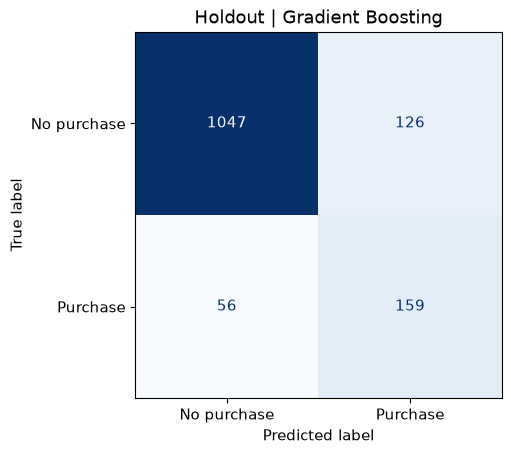

Holdout F1 is **0.6360** (bootstrap 95% interval 0.586–0.684) against a CV estimate of 0.6936. The CV estimate falls outside the interval, so the holdout result is genuinely lower than cross-validation suggested. We report it as a limitation and do not revisit the model choice, since tuning against the holdout would turn it into another validation set.

In [33]:
from sklearn.metrics import precision_score, recall_score

holdout_model = build_final_model().fit(X_dev, y_dev)
holdout_pred = holdout_model.predict(X_holdout)

holdout_f1 = f1_score(y_holdout, holdout_pred)
holdout_summary = pd.DataFrame([{
    "Model": final_name,
    "Decision rule": selected["Decision rule"],
    "Threshold": getattr(holdout_model, "best_threshold_", 0.5),
    "CV F1 (dev)": selected["CV F1"],
    "Holdout F1": holdout_f1,
    "Holdout precision": precision_score(y_holdout, holdout_pred),
    "Holdout recall": recall_score(y_holdout, holdout_pred),
    "Holdout positives": int(y_holdout.sum()),
}])
display(holdout_summary.round(4))
holdout_summary.to_csv("task5_holdout_check.csv", index=False)

print(classification_report(
    y_holdout, holdout_pred, labels=[0, 1],
    target_names=["No Purchase", "Purchase"], digits=3, zero_division=0,
))

fig, ax = plt.subplots(figsize=(5, 4.5), layout="constrained")
ConfusionMatrixDisplay(
    confusion_matrix(y_holdout, holdout_pred, labels=[0, 1]),
    display_labels=["No purchase", "Purchase"],
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title(f"Holdout | {final_name}")
fig.savefig("task5_holdout_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

# Bootstrap the holdout rows to see how much F1 varies from sampling alone.
rng = np.random.default_rng(42)
y_h, p_h = y_holdout.to_numpy(), np.asarray(holdout_pred)
boot_f1 = np.array([
    f1_score(y_h[idx], p_h[idx])
    for idx in (rng.integers(0, len(y_h), len(y_h)) for _ in range(2000))
])
ci_low, ci_high = np.percentile(boot_f1, [2.5, 97.5])
cv_inside = ci_low <= selected["CV F1"] <= ci_high

display(Markdown(
    f"Holdout F1 is **{holdout_f1:.4f}** (bootstrap 95% interval "
    f"{ci_low:.3f}–{ci_high:.3f}) against a CV estimate of {selected['CV F1']:.4f}. "
    + ("The CV estimate falls inside the interval, so the gap is consistent with "
       "sampling noise on a holdout of this size." if cv_inside else
       "The CV estimate falls outside the interval, so the holdout result is "
       "genuinely lower than cross-validation suggested. We report it as a "
       "limitation and do not revisit the model choice, since tuning against the "
       "holdout would turn it into another validation set.")
))

### 5.3 What drives the predictions

Impurity-based importances from the selected model (fitted on the development set)
give a coarse view of which inputs it relies on. One-hot columns are summed back to
their original feature so categories are comparable with numeric features.

In [34]:
fitted_pipeline = (
    holdout_model.estimator_ if use_tuned_threshold else holdout_model
)
encoded_names = fitted_pipeline.named_steps["preprocessor"].get_feature_names_out()
importances = pd.Series(
    fitted_pipeline.named_steps["model"].feature_importances_, index=encoded_names
)

def original_feature(encoded):
    block, column = encoded.split("__", 1)
    if block == "cat":
        for feature in categorical_features:
            if column.startswith(feature + "_"):
                return feature
    return column

feature_importance = (
    importances.groupby(importances.index.map(original_feature)).sum()
    .sort_values(ascending=False)
)
display(feature_importance.round(4).to_frame("Importance").head(10))

,Importance
PageValues,0.7644
Month,0.0464
BounceRates,0.0352
ExitRates,0.0298
Administrative,0.0270
ProductRelated,0.0268
ProductRelated_Duration,0.0239
VisitorType,0.0126
Administrative_Duration,0.0111
TrafficType,0.0069


### 5.4 Justification

- **Validation performance.** With nested threshold tuning, Gradient Boosting
  reaches a mean outer CV F1 of about 0.694, up from 0.680 at the 0.5 cutoff.
  That gain is larger than the one from hyperparameter tuning alone (0.673 to 0.680).
  Lowering the cutoff to about 0.3 trades some precision for many more recovered
  purchases (recall rises from 0.63 to 0.77). Because the threshold is chosen inside
  each training fold, the gain is measured on folds that never influenced it.
  Random Forest with a tuned threshold scores almost the same (about 0.691). Under
  the pre-set rule, that counts as a tie.
- **Overfitting.** The tie-break decides it. Gradient Boosting's train/validation F1
  gap is about 0.05, compared with about 0.18 for Random Forest, whose
  unrestricted-depth trees nearly memorize the training folds. A model that fits
  training data less tightly for the same validation score is the safer bet on
  unseen data. The holdout check came in below the CV estimate (see 5.2). That
  is the most realistic signal we have about test performance, and we report it
  rather than tune against it.
- **Complexity and computation.** The final model is 200 depth-3 trees with a
  learning rate of 0.05 plus one probability threshold. It fits in about a second
  per fold, and the nested threshold search multiplies that only by the 5 inner
  folds. That is cheap at this data size.
- **Interpretability.** It is less transparent than Logistic Regression or a single
  tree, but the importance table shows it relies on sensible signals, led by
  `PageValues`, which the Task 1 exploration identified as the strongest predictor.
  The linear and single-tree baselines scored far lower F1 in Task 3, so the
  accuracy gain justifies the loss of transparency.

## Task 6: Generate Predictions

The selected procedure is refitted on **all** labeled rows (development plus
holdout). With threshold tuning, this reruns the inner 5-fold threshold search on
the full training set, so the final threshold also uses all available labels. The
test features are used only here, for prediction. `predictions.csv` holds `ID` and
the predicted `Revenue` class as `True`/`False`, in the original test order.

In [35]:
final_model = build_final_model().fit(X, y)
final_threshold = getattr(final_model, "best_threshold_", 0.5)

test_pred = final_model.predict(X_test).astype(bool)
predictions = pd.DataFrame({"ID": test_ids.to_numpy(), "Revenue": test_pred})

# Submission checks: every test ID, original order, no gaps, boolean classes.
assert len(predictions) == len(test) == 3083
assert predictions["ID"].tolist() == test["ID"].tolist()
assert predictions["ID"].is_unique
assert predictions.notna().all().all()
assert predictions["Revenue"].dtype == bool

predictions.to_csv("predictions.csv", index=False)

saved = pd.read_csv("predictions.csv")
assert saved.columns.tolist() == ["ID", "Revenue"]
assert set(saved["Revenue"].unique()) <= {True, False}
assert saved["ID"].tolist() == test["ID"].tolist()

print(f"Final model: {final_name}, threshold {final_threshold:.3f}")
print(f"Wrote predictions.csv: {len(saved)} rows")
print(f"Predicted purchase rate on test: {saved['Revenue'].mean():.3f} "
      f"(training positive rate {y.mean():.3f})")
display(saved.head())

Final model: Gradient Boosting, threshold 0.338
Wrote predictions.csv: 3083 rows
Predicted purchase rate on test: 0.172 (training positive rate 0.155)


,ID,Revenue
0,2,False
1,5,False
2,6,False
3,8,False
4,10,False


The predicted purchase rate is higher than the 15.5% base rate. That is
expected: the F1-optimal threshold deliberately accepts extra false positives in
exchange for catching more true purchases. The notebook has now run end to end, from
loading the data to writing the final predictions.